In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

SEED = 42
keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("CPU devices:", tf.config.list_physical_devices("CPU"))

try:
    if tf.config.list_physical_devices("GPU"):
        from tensorflow.keras import mixed_precision
        mixed_precision.set_global_policy("mixed_float16")
        print("Mixed precision enabled.")
    else:
        print("Running without mixed precision (no GPU detected).")
except Exception as e:
    print("Mixed precision not enabled:", e)

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Mixed precision enabled.


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/MEDICAL-AI-PROJECT")

# Correct dataset location
DRIVE_DATA_DIR = PROJECT_DIR / "chest-xray"

# Copy to Colab (faster training)
LOCAL_DATA_DIR = Path("/content/chest-xray")

if LOCAL_DATA_DIR.exists():
    shutil.rmtree(LOCAL_DATA_DIR)

shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)

train_dir = LOCAL_DATA_DIR / "train"
test_dir  = LOCAL_DATA_DIR / "test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
VAL_SPLIT = 0.20

assert train_dir.exists(), f"Train path not found: {train_dir}"
assert test_dir.exists(), f"Test path not found: {test_dir}"

print("Using dataset from:", LOCAL_DATA_DIR)
print("Train:", train_dir)
print("Test :", test_dir)

Using dataset from: /content/chest-xray
Train: /content/chest-xray/train
Test : /content/chest-xray/test


In [4]:
def count_images_in_split(split_path):
    split_path = Path(split_path)
    counts = {}
    total = 0
    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name
        if class_path.is_dir():
            n = len([f for f in class_path.iterdir() if f.is_file()])
            counts[class_name] = n
            total += n
    return counts, total

train_counts, train_total = count_images_in_split(train_dir)
test_counts, test_total = count_images_in_split(test_dir)

estimated_val_total = int(round(train_total * VAL_SPLIT))
estimated_train_total = train_total - estimated_val_total

df_counts = pd.DataFrame([
    {
        "split": "original_train_total",
        "total": train_total,
        **train_counts
    },
    {
        "split": "new_train_estimated",
        "total": estimated_train_total
    },
    {
        "split": "new_val_estimated",
        "total": estimated_val_total
    },
    {
        "split": "test",
        "total": test_total,
        **test_counts
    }
]).fillna(0)

display(df_counts)

,split,total,NORMAL,PNEUMONIA
0,original_train_total,5216,1341.0,3875.0
1,new_train_estimated,4173,0.0,0.0
2,new_val_estimated,1043,0.0,0.0
3,test,624,234.0,390.0


In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Class names:", class_names)
print("Train batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Class names: ['NORMAL', 'PNEUMONIA']
Train batches: 131
Validation batches: 33
Test batches: 20


In [6]:
def inspect_dataset_labels(ds, name):
    labels = []

    for _, y in ds.unbatch():
        labels.append(int(y.numpy().item()))

    labels = np.array(labels)

    unique, counts = np.unique(labels, return_counts=True)
    mapping = {int(k): int(v) for k, v in zip(unique, counts)}

    print(f"{name} size:", len(labels))
    print(f"{name} label counts:", mapping)

    if len(unique) < 2:
        print(f"WARNING: {name} contains only one class!")
    else:
        print(f"{name} contains both classes correctly.")


inspect_dataset_labels(train_ds, "Train")
inspect_dataset_labels(val_ds, "Validation")
inspect_dataset_labels(test_ds, "Test")

Train size: 4173
Train label counts: {0: 1092, 1: 3081}
Train contains both classes correctly.
Validation size: 1043
Validation label counts: {0: 249, 1: 794}
Validation contains both classes correctly.
Test size: 624
Test label counts: {0: 234, 1: 390}
Test contains both classes correctly.


In [7]:
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

/tmp/ipykernel_22330/919481379.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  label_idx = int(labels[i].numpy())  # ✅ FIXED


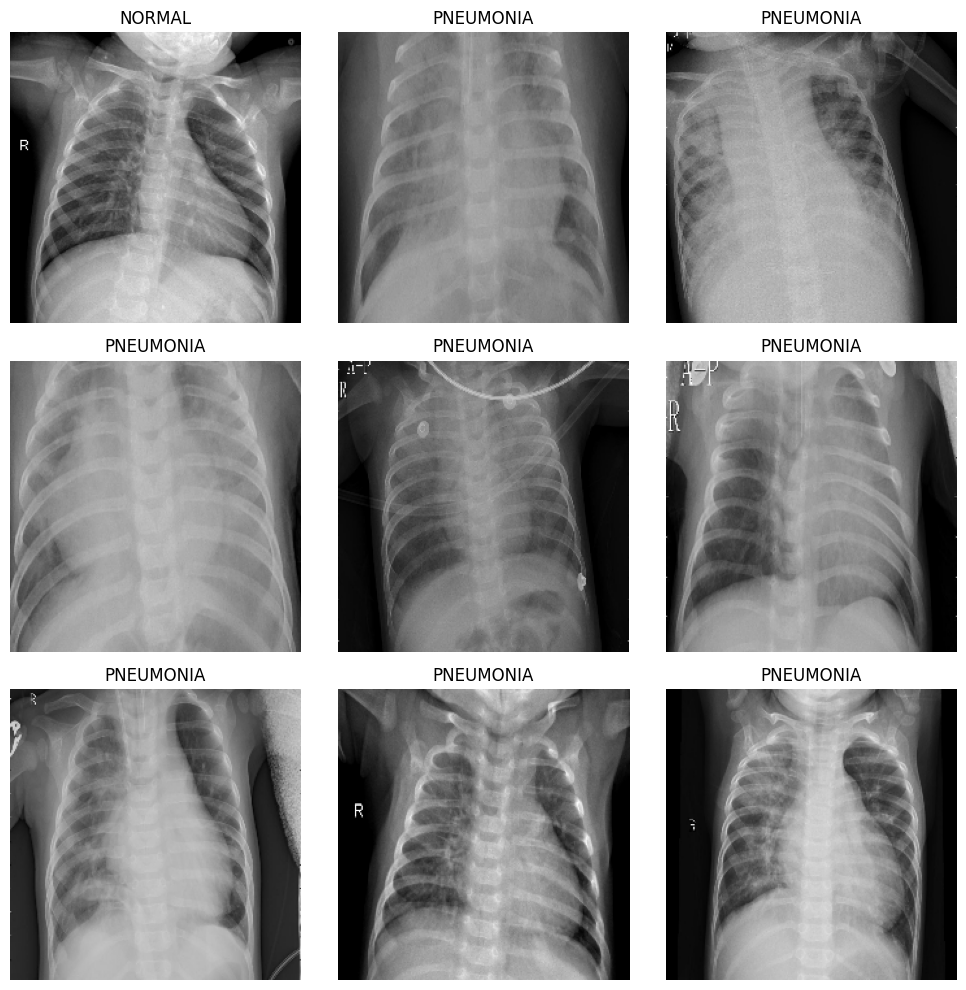

In [8]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_idx = int(labels[i].numpy())  # ✅ FIXED
        plt.title(class_names[label_idx])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03),
    layers.RandomContrast(0.05),
], name="data_augmentation")

y_train = []
for _, labels in train_ds.unbatch():
    y_train.append(int(labels.numpy().item()))

y_train = np.array(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight = {i: float(w) for i, w in enumerate(class_weights_array)}
print("Class weight:", class_weight)

Class weight: {0: 1.9107142857142858, 1: 0.6772151898734177}


In [10]:
def get_backbone_and_preprocess(model_name, input_shape=(224, 224, 3)):
    model_name = model_name.lower()

    if model_name == "mobilenetv2":
        preprocess = tf.keras.applications.mobilenet_v2.preprocess_input
        backbone = tf.keras.applications.MobileNetV2(
            input_shape=input_shape,
            include_top=False,
            weights="imagenet"
        )
    elif model_name == "efficientnetb0":
        preprocess = tf.keras.applications.efficientnet.preprocess_input
        backbone = tf.keras.applications.EfficientNetB0(
            input_shape=input_shape,
            include_top=False,
            weights="imagenet"
        )
    else:
        raise ValueError("Unsupported model_name. Use 'mobilenetv2' or 'efficientnetb0'.")

    return backbone, preprocess


def build_model(model_name, input_shape=(224, 224, 3), dropout_rate=0.45, l2_value=1e-4):
    inputs = keras.Input(shape=input_shape)

    x = data_augmentation(inputs)
    backbone, preprocess = get_backbone_and_preprocess(model_name, input_shape)
    x = preprocess(x)

    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(l2_value)
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)

    model = keras.Model(inputs, outputs, name=f"{model_name}_pneumonia")
    return model, backbone

In [11]:
def compile_model(model, lr=3e-4, label_smoothing=0.02):
    optimizer = keras.optimizers.Adam(learning_rate=lr)

    # If mixed precision is active → wrap optimizer (safe practice)
    try:
        from tensorflow.keras import mixed_precision
        if mixed_precision.global_policy().name == "mixed_float16":
            optimizer = mixed_precision.LossScaleOptimizer(optimizer)
    except:
        pass

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

In [12]:
def plot_history(history1, history2=None, title_prefix=""):
    histories = [history1] if history2 is None else [history1, history2]
    merged = {}

    for h in histories:
        for k, v in h.history.items():
            merged.setdefault(k, []).extend(v)

    for metric in ["loss", "accuracy", "precision", "recall", "auc"]:
        if metric in merged and f"val_{metric}" in merged:
            plt.figure(figsize=(7, 4.5))
            plt.plot(merged[metric], label=f"train_{metric}")
            plt.plot(merged[f"val_{metric}"], label=f"val_{metric}")
            plt.title(f"{title_prefix}{metric}")
            plt.xlabel("Epoch")
            plt.ylabel(metric)
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.show()

In [21]:
def evaluate_model(model, dataset, threshold=0.5):
    y_true, y_prob = [], []

    for images, labels in dataset:
        probs = model.predict(images, verbose=0).ravel()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.numpy().astype(int).ravel().tolist())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    try:
        auc = float(roc_auc_score(y_true, y_prob))
    except:
        auc = 0.0

    normal_recall = tn / (tn + fp + 1e-8)
    pneumonia_recall = tp / (tp + fn + 1e-8)

    results = {
        "threshold": float(threshold),
        "accuracy": float(np.mean(y_pred == y_true)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "normal_recall": float(normal_recall),
        "pneumonia_recall": float(pneumonia_recall),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "auc": auc
    }

    return results, y_true, y_prob, y_pred


def find_best_threshold(
    model,
    val_ds,
    min_pneumonia_recall=0.95,
    target_normal_recall=0.85
):
    y_true, y_prob = [], []

    for images, labels in val_ds:
        probs = model.predict(images, verbose=0).ravel()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.numpy().astype(int).ravel().tolist())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)

    thresholds = np.arange(0.05, 0.96, 0.01)
    rows = []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

        normal_recall = tn / (tn + fp + 1e-8)
        pneumonia_recall = tp / (tp + fn + 1e-8)

        rows.append({
            "threshold": float(t),
            "accuracy": float(np.mean(y_pred == y_true)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "pneumonia_recall": float(pneumonia_recall),
            "normal_recall": float(normal_recall),
            "false_positives": int(fp),
            "false_negatives": int(fn),
            "f1": float(f1_score(y_true, y_pred, zero_division=0))
        })

    threshold_df = pd.DataFrame(rows)

    # Main rule:
    # Keep pneumonia recall high, but choose the threshold that reduces false positives.
    candidates = threshold_df[
        threshold_df["pneumonia_recall"] >= min_pneumonia_recall
    ]

    strong_candidates = candidates[
        candidates["normal_recall"] >= target_normal_recall
    ]

    if len(strong_candidates) > 0:
        candidates = strong_candidates

    if len(candidates) == 0:
        print("No threshold kept pneumonia recall high enough.")
        print("Using best balanced fallback.")
        candidates = threshold_df.copy()

    best_row = candidates.sort_values(
        by=["normal_recall", "precision", "f1", "accuracy"],
        ascending=False
    ).iloc[0]

    best_threshold = float(best_row["threshold"])

    print("Best threshold:", best_threshold)
    print("Selected threshold row:")
    display(pd.DataFrame([best_row]))

    print("Top thresholds focused on fewer false positives:")
    display(
        threshold_df.sort_values(
            by=["normal_recall", "pneumonia_recall", "f1"],
            ascending=False
        ).head(20)
    )

    return best_threshold, threshold_df

In [22]:
def train_and_finetune(model_name, phase1_epochs=8, phase2_epochs=10, unfreeze_last_layers=40):
    print("=" * 80)
    print(f"Training {model_name}")
    print("=" * 80)

    # Build model
    model, backbone = build_model(model_name, input_shape=IMG_SIZE + (3,))

    # Compile phase 1
    compile_model(model, lr=3e-4, label_smoothing=0.02)

    # Save models directly inside your Google Drive project
    SAVE_DIR = PROJECT_DIR / "models"
    SAVE_DIR.mkdir(parents=True, exist_ok=True)

    phase1_ckpt = SAVE_DIR / f"best_{model_name}_phase1.keras"
    final_ckpt = SAVE_DIR / f"best_{model_name}_final.keras"

    # =========================
    # Phase 1 callbacks
    # =========================
    callbacks_phase1 = [
        ModelCheckpoint(
            str(phase1_ckpt),
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    # =========================
    # Phase 1 training
    # =========================
    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=phase1_epochs,
        class_weight=class_weight,
        callbacks=callbacks_phase1,
        verbose=1
    )

    # Load best phase 1 checkpoint
    model = keras.models.load_model(str(phase1_ckpt))

    # =========================
    # Find backbone after loading
    # =========================
    loaded_backbone = None

    for layer in model.layers:
        if isinstance(layer, keras.Model) and (
            "mobilenetv2" in layer.name.lower()
            or "efficientnetb0" in layer.name.lower()
        ):
            loaded_backbone = layer
            break

    if loaded_backbone is None:
        raise ValueError(f"Could not find backbone for {model_name} after loading checkpoint.")

    # =========================
    # Fine-tuning setup
    # =========================
    loaded_backbone.trainable = True

    if unfreeze_last_layers is not None and unfreeze_last_layers > 0:
        for layer in loaded_backbone.layers[:-unfreeze_last_layers]:
            layer.trainable = False

    # Keep BatchNorm frozen during fine-tuning
    for layer in loaded_backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    # Compile phase 2 with smaller learning rate
    compile_model(model, lr=1e-5, label_smoothing=0.01)

    # =========================
    # Phase 2 callbacks
    # =========================
    callbacks_phase2 = [
        ModelCheckpoint(
            str(final_ckpt),
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

    # =========================
    # Phase 2 fine-tuning
    # =========================
    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=phase2_epochs,
        class_weight=class_weight,
        callbacks=callbacks_phase2,
        verbose=1
    )

    # =========================
    # Load best final model
    # =========================
    best_model = keras.models.load_model(str(final_ckpt))

    # =========================
    # Find best threshold using validation set
    # This is to reduce false positives
    # =========================
    best_threshold, threshold_df = find_best_threshold(
        best_model,
        val_ds,
        min_pneumonia_recall=0.95,
        target_normal_recall=0.85
    )

    # =========================
    # Evaluate using tuned threshold
    # =========================
    val_metrics, _, _, _ = evaluate_model(
        best_model,
        val_ds,
        threshold=best_threshold
    )

    test_metrics, y_true, y_prob, y_pred = evaluate_model(
        best_model,
        test_ds,
        threshold=best_threshold
    )

    # =========================
    # Return all results
    # =========================
    return {
        "model_name": model_name,
        "history_phase1": history1,
        "history_phase2": history2,
        "best_model": best_model,
        "val_metrics": val_metrics,
        "test_metrics": test_metrics,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "threshold": best_threshold,
        "threshold_df": threshold_df,
        "checkpoint": str(final_ckpt)
    }

In [15]:
mobilenet_results = train_and_finetune(
    model_name="mobilenetv2",
    phase1_epochs=8,
    phase2_epochs=10,
    unfreeze_last_layers=30
)

# Clear memory before second model (IMPORTANT on Colab)
tf.keras.backend.clear_session()

efficientnet_results = train_and_finetune(
    model_name="efficientnetb0",
    phase1_epochs=8,
    phase2_epochs=10,
    unfreeze_last_layers=60
)

Training mobilenetv2
Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.7080 - auc: 0.8299 - loss: 0.5660 - precision: 0.9274 - recall: 0.6645
Epoch 1: val_auc improved from None to 0.96915, saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_mobilenetv2_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_mobilenetv2_phase1.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 69s 324ms/step - accuracy: 0.7846 - auc: 0.9220 - loss: 0.4338 - precision: 0.9615 - recall: 0.7377 - val_accuracy: 0.9310 - val_auc: 0.9691 - val_loss: 0.2654 - val_precision: 0.9616 - val_recall: 0.9471 - learning_rate: 3.0000e-04
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8618 - auc: 0.9721 - loss: 0.2977 - precision: 0.9845 - recall: 0.8275
Epoch 2: val_auc improved from 0.96915 to 0.97595, saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_mobilenetv2_phase1.keras

Epoch 2: finished saving model to /con

,threshold,accuracy,precision,recall,normal_recall,false_positives,false_negatives,f1
7,0.12,0.972196,0.973978,0.989924,0.915663,21.0,8.0,0.981886


Top threshold candidates:


,threshold,accuracy,precision,recall,normal_recall,false_positives,false_negatives,f1
7,0.12,0.972196,0.973978,0.989924,0.915663,21,8,0.981886
24,0.29,0.972196,0.984791,0.978589,0.951807,12,17,0.981680
10,0.15,0.971237,0.977500,0.984887,0.927711,18,12,0.981179
18,0.23,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
19,0.24,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
20,0.25,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
21,0.26,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
22,0.27,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
23,0.28,0.971237,0.983544,0.978589,0.947791,13,17,0.981061
25,0.30,0.971237,0.984772,0.977330,0.951807,12,18,0.981037


Training efficientnetb0
Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7570 - auc: 0.8751 - loss: 0.5087 - precision: 0.9421 - recall: 0.7112
Epoch 1: val_auc improved from None to 0.98149, saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_efficientnetb0_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_efficientnetb0_phase1.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 147ms/step - accuracy: 0.8021 - auc: 0.9294 - loss: 0.4178 - precision: 0.9680 - recall: 0.7569 - val_accuracy: 0.9291 - val_auc: 0.9815 - val_loss: 0.3186 - val_precision: 0.9675 - val_recall: 0.9383 - learning_rate: 3.0000e-04
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.8690 - auc: 0.9698 - loss: 0.3031 - precision: 0.9892 - recall: 0.8335
Epoch 2: val_auc improved from 0.98149 to 0.98700, saving model to /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_efficientnetb0_phase1.keras

Epoch 2: finished saving mo

,threshold,accuracy,precision,recall,normal_recall,false_positives,false_negatives,f1
17,0.22,0.976989,0.982456,0.987406,0.943775,14.0,10.0,0.984925


Top threshold candidates:


,threshold,accuracy,precision,recall,normal_recall,false_positives,false_negatives,f1
17,0.22,0.976989,0.982456,0.987406,0.943775,14,10,0.984925
23,0.28,0.976989,0.987342,0.982368,0.959839,10,14,0.984848
24,0.29,0.976989,0.988579,0.981108,0.963855,9,15,0.984829
26,0.31,0.976989,0.989822,0.979849,0.967871,8,16,0.984810
27,0.32,0.976989,0.991071,0.978589,0.971888,7,17,0.984791
28,0.33,0.976989,0.991071,0.978589,0.971888,7,17,0.984791
29,0.34,0.976989,0.991071,0.978589,0.971888,7,17,0.984791
30,0.35,0.976989,0.992327,0.977330,0.975904,6,18,0.984772
31,0.36,0.976989,0.992327,0.977330,0.975904,6,18,0.984772
32,0.37,0.976989,0.992327,0.977330,0.975904,6,18,0.984772


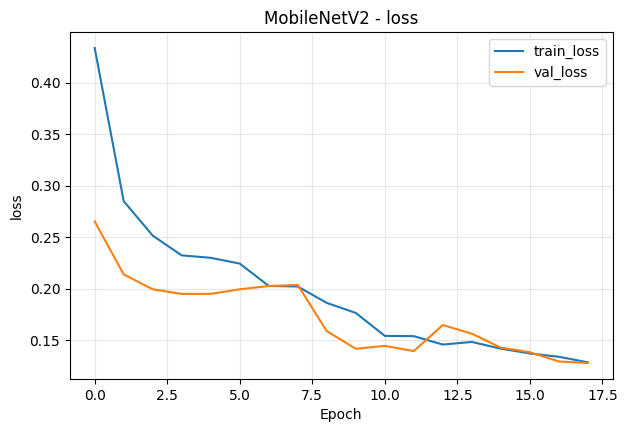

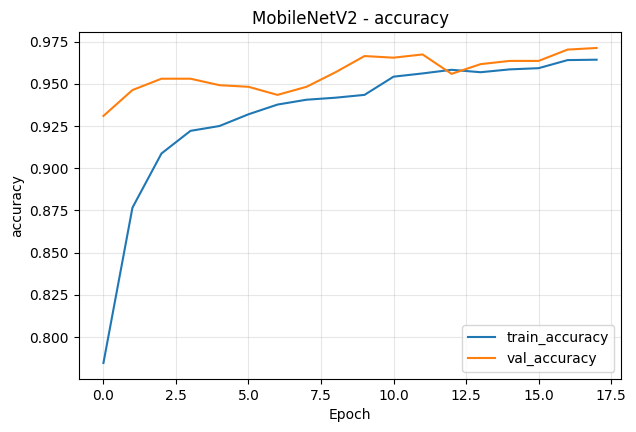

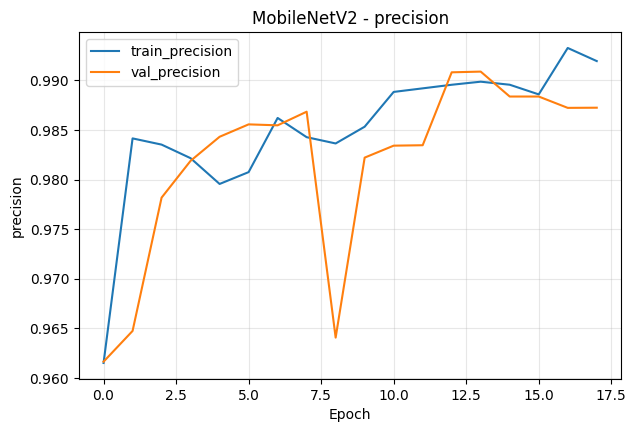

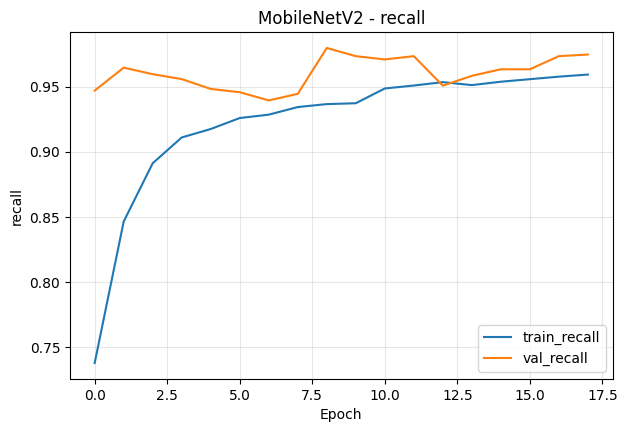

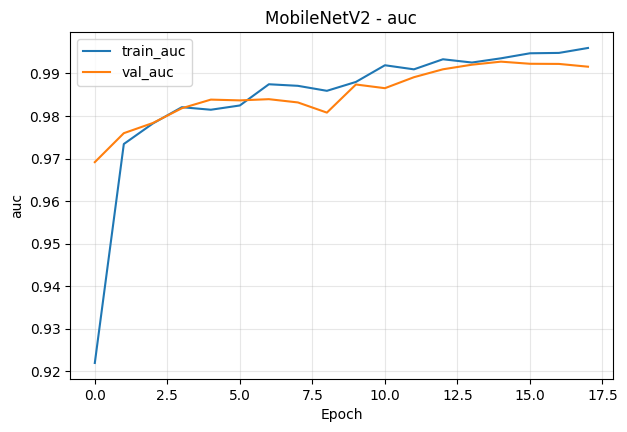

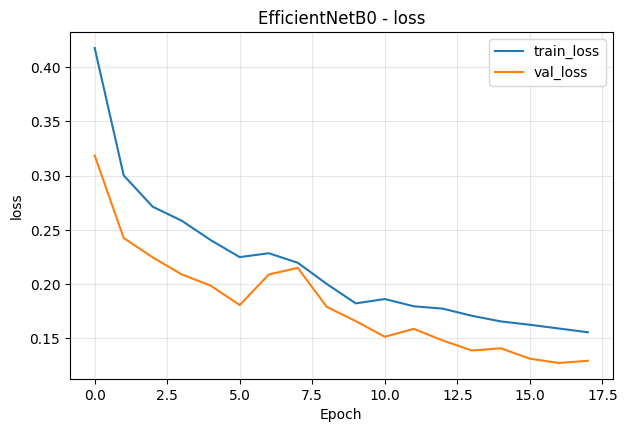

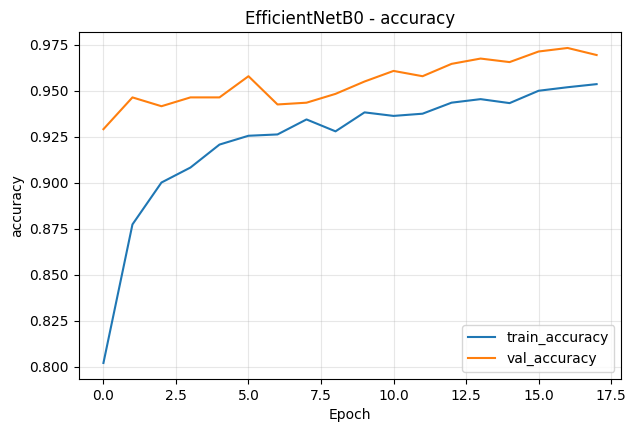

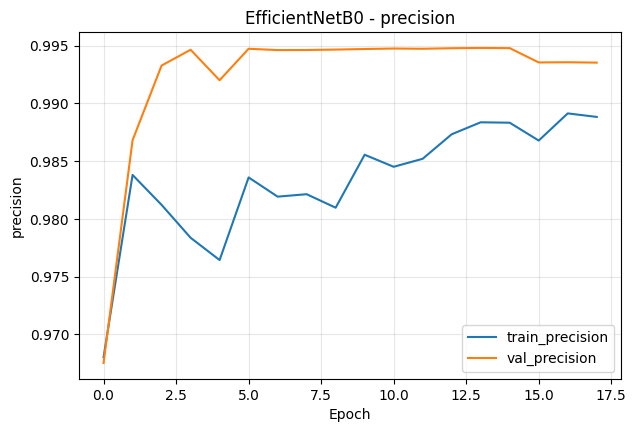

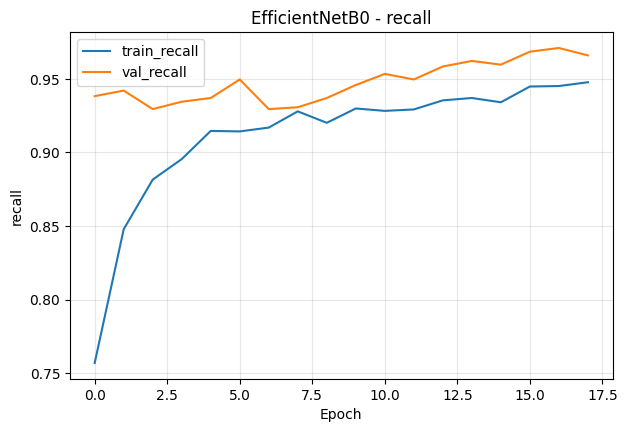

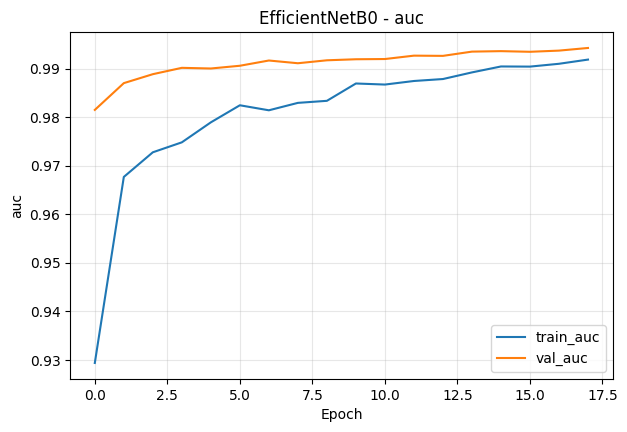

In [23]:
plot_history(
    mobilenet_results["history_phase1"],
    mobilenet_results["history_phase2"],
    title_prefix="MobileNetV2 - "
)

plot_history(
    efficientnet_results["history_phase1"],
    efficientnet_results["history_phase2"],
    title_prefix="EfficientNetB0 - "
)

In [24]:
for result in [mobilenet_results, efficientnet_results]:
    print("=" * 80)
    print("Retuning threshold for:", result["model_name"])
    print("=" * 80)

    best_model = result["best_model"]

    best_threshold, threshold_df = find_best_threshold(
        best_model,
        val_ds,
        min_pneumonia_recall=0.95,
        target_normal_recall=0.85
    )

    val_metrics, _, _, _ = evaluate_model(
        best_model,
        val_ds,
        threshold=best_threshold
    )

    test_metrics, y_true, y_prob, y_pred = evaluate_model(
        best_model,
        test_ds,
        threshold=best_threshold
    )

    result["threshold"] = best_threshold
    result["threshold_df"] = threshold_df
    result["val_metrics"] = val_metrics
    result["test_metrics"] = test_metrics
    result["y_true"] = y_true
    result["y_prob"] = y_prob
    result["y_pred"] = y_pred

Retuning threshold for: mobilenetv2
Best threshold: 0.6300000000000001
Selected threshold row:


,threshold,accuracy,precision,pneumonia_recall,normal_recall,false_positives,false_negatives,f1
58,0.63,0.961649,0.994751,0.95466,0.983936,4.0,36.0,0.974293


Top thresholds focused on fewer false positives:


,threshold,accuracy,precision,pneumonia_recall,normal_recall,false_positives,false_negatives,f1
83,0.88,0.906040,0.997143,0.879093,0.991968,2,96,0.934404
84,0.89,0.903164,0.997131,0.875315,0.991968,2,99,0.932260
85,0.90,0.893576,0.997089,0.862720,0.991968,2,109,0.925051
86,0.91,0.884947,0.997050,0.851385,0.991968,2,118,0.918478
87,0.92,0.877277,0.997015,0.841310,0.991968,2,126,0.912568
88,0.93,0.865772,0.996960,0.826196,0.991968,2,138,0.903581
89,0.94,0.850431,0.996885,0.806045,0.991968,2,154,0.891365
90,0.95,0.836050,0.996810,0.787154,0.991968,2,169,0.879662
78,0.83,0.926174,0.995851,0.906801,0.987952,3,74,0.949242
79,0.84,0.924257,0.995839,0.904282,0.987952,3,76,0.947855


Retuning threshold for: efficientnetb0
Best threshold: 0.5100000000000001
Selected threshold row:


,threshold,accuracy,precision,pneumonia_recall,normal_recall,false_positives,false_negatives,f1
46,0.51,0.970278,0.994812,0.965995,0.983936,4.0,27.0,0.980192


Top thresholds focused on fewer false positives:


,threshold,accuracy,precision,pneumonia_recall,normal_recall,false_positives,false_negatives,f1
85,0.90,0.905081,0.997139,0.877834,0.991968,2,97,0.933691
86,0.91,0.895494,0.997097,0.865239,0.991968,2,107,0.926500
87,0.92,0.883988,0.997046,0.850126,0.991968,2,119,0.917743
88,0.93,0.869607,0.996979,0.831234,0.991968,2,134,0.906593
89,0.94,0.859060,0.996928,0.817380,0.991968,2,145,0.898270
90,0.95,0.829338,0.996774,0.778338,0.991968,2,176,0.874116
72,0.77,0.944391,0.995957,0.930730,0.987952,3,55,0.962240
73,0.78,0.941515,0.995940,0.926952,0.987952,3,58,0.960209
74,0.79,0.940556,0.995935,0.925693,0.987952,3,59,0.959530
75,0.80,0.940556,0.995935,0.925693,0.987952,3,59,0.959530


In [25]:
comparison_rows = []

for result in [mobilenet_results, efficientnet_results]:
    comparison_rows.append({
        "model": result["model_name"],
        "threshold": round(result["threshold"], 3),

        "val_accuracy": round(result["val_metrics"]["accuracy"], 4),
        "val_precision": round(result["val_metrics"]["precision"], 4),
        "val_recall": round(result["val_metrics"]["recall"], 4),
        "val_normal_recall": round(result["val_metrics"]["normal_recall"], 4),
        "val_false_positives": result["val_metrics"]["false_positives"],
        "val_false_negatives": result["val_metrics"]["false_negatives"],
        "val_f1": round(result["val_metrics"]["f1"], 4),
        "val_auc": round(result["val_metrics"]["auc"], 4),

        "test_accuracy": round(result["test_metrics"]["accuracy"], 4),
        "test_precision": round(result["test_metrics"]["precision"], 4),
        "test_recall": round(result["test_metrics"]["recall"], 4),
        "test_normal_recall": round(result["test_metrics"]["normal_recall"], 4),
        "test_false_positives": result["test_metrics"]["false_positives"],
        "test_false_negatives": result["test_metrics"]["false_negatives"],
        "test_f1": round(result["test_metrics"]["f1"], 4),
        "test_auc": round(result["test_metrics"]["auc"], 4),

        "saved_model": result["checkpoint"]
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by=["test_normal_recall", "test_f1", "test_recall", "test_auc"],
    ascending=False
).reset_index(drop=True)

display(comparison_df)

,model,threshold,val_accuracy,val_precision,val_recall,val_normal_recall,val_false_positives,val_false_negatives,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_normal_recall,test_false_positives,test_false_negatives,test_f1,test_auc,saved_model
0,mobilenetv2,0.63,0.9616,0.9948,0.9547,0.9839,4,36,0.9743,0.9925,0.8798,0.8523,0.9769,0.7179,66,9,0.9104,0.9666,/content/drive/MyDrive/MEDICAL-AI-PROJECT/mode...
1,efficientnetb0,0.51,0.9703,0.9948,0.9660,0.9839,4,27,0.9802,0.9942,0.8542,0.8201,0.9821,0.6410,84,7,0.8938,0.9593,/content/drive/MyDrive/MEDICAL-AI-PROJECT/mode...


In [26]:
best_model_name = comparison_df.iloc[0]["model"]
best_threshold = comparison_df.iloc[0]["threshold"]

print("Best model focused on reducing false positives:", best_model_name)
print("Selected threshold:", best_threshold)

Best model focused on reducing false positives: mobilenetv2
Selected threshold: 0.63



MobileNetV2

Validation metrics:
threshold: 0.6300
accuracy: 0.9616
precision: 0.9948
recall: 0.9547
normal_recall: 0.9839
pneumonia_recall: 0.9547
false_positives: 4.0000
false_negatives: 36.0000
f1: 0.9743
auc: 0.9925

Test metrics:
threshold: 0.6300
accuracy: 0.8798
precision: 0.8523
recall: 0.9769
normal_recall: 0.7179
pneumonia_recall: 0.9769
false_positives: 66.0000
false_negatives: 9.0000
f1: 0.9104
auc: 0.9666

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9492    0.7179    0.8175       234
   PNEUMONIA     0.8523    0.9769    0.9104       390

    accuracy                         0.8798       624
   macro avg     0.9008    0.8474    0.8640       624
weighted avg     0.8887    0.8798    0.8756       624



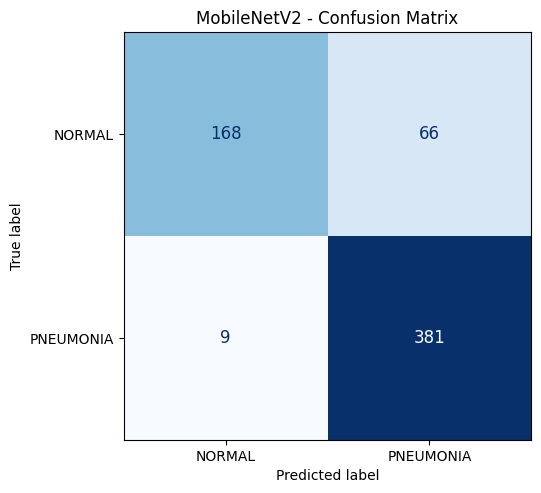


EfficientNetB0

Validation metrics:
threshold: 0.5100
accuracy: 0.9703
precision: 0.9948
recall: 0.9660
normal_recall: 0.9839
pneumonia_recall: 0.9660
false_positives: 4.0000
false_negatives: 27.0000
f1: 0.9802
auc: 0.9942

Test metrics:
threshold: 0.5100
accuracy: 0.8542
precision: 0.8201
recall: 0.9821
normal_recall: 0.6410
pneumonia_recall: 0.9821
false_positives: 84.0000
false_negatives: 7.0000
f1: 0.8938
auc: 0.9593

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9554    0.6410    0.7673       234
   PNEUMONIA     0.8201    0.9821    0.8938       390

    accuracy                         0.8542       624
   macro avg     0.8878    0.8115    0.8305       624
weighted avg     0.8709    0.8542    0.8464       624



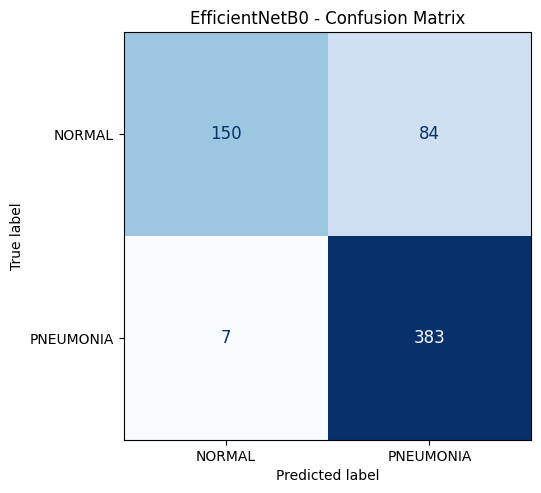

In [27]:
def show_report_and_confusion(result, title):
    print("\n" + "="*70)
    print(title)
    print("="*70)

    print("\nValidation metrics:")
    for k, v in result["val_metrics"].items():
        print(f"{k}: {v:.4f}")

    print("\nTest metrics:")
    for k, v in result["test_metrics"].items():
        print(f"{k}: {v:.4f}")

    print("\nClassification report:")
    print(classification_report(
        result["y_true"],
        result["y_pred"],
        target_names=class_names,
        digits=4
    ))

    cm = confusion_matrix(result["y_true"], result["y_pred"])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)

    # ✅ Add numbers formatting for clarity
    for text in ax.texts:
        text.set_fontsize(12)

    plt.title(f"{title} - Confusion Matrix")
    plt.tight_layout()
    plt.show()


show_report_and_confusion(mobilenet_results, "MobileNetV2")
show_report_and_confusion(efficientnet_results, "EfficientNetB0")

In [29]:
def test_threshold_sweep(model, test_ds, thresholds):
    rows = []

    for threshold in thresholds:
        metrics, y_true, y_prob, y_pred = evaluate_model(
            model,
            test_ds,
            threshold=threshold
        )

        rows.append({
            "threshold": threshold,
            "accuracy": round(metrics["accuracy"], 4),
            "precision": round(metrics["precision"], 4),
            "pneumonia_recall": round(metrics["pneumonia_recall"], 4),
            "normal_recall": round(metrics["normal_recall"], 4),
            "false_positives": metrics["false_positives"],
            "false_negatives": metrics["false_negatives"],
            "f1": round(metrics["f1"], 4),
            "auc": round(metrics["auc"], 4)
        })

    df = pd.DataFrame(rows)
    display(df)

    return df


mobilenet_threshold_test_df = test_threshold_sweep(
    mobilenet_results["best_model"],
    test_ds,
    thresholds=[0.50, 0.55, 0.60, 0.63, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]
)

,threshold,accuracy,precision,pneumonia_recall,normal_recall,false_positives,false_negatives,f1,auc
0,0.50,0.8734,0.8403,0.9846,0.6880,73,6,0.9067,0.9666
1,0.55,0.8766,0.8440,0.9846,0.6966,71,6,0.9089,0.9666
2,0.60,0.8750,0.8451,0.9795,0.7009,70,8,0.9074,0.9666
3,0.63,0.8798,0.8523,0.9769,0.7179,66,9,0.9104,0.9666
4,0.65,0.8830,0.8562,0.9769,0.7265,64,9,0.9126,0.9666
5,0.70,0.8942,0.8733,0.9718,0.7650,55,11,0.9199,0.9666
6,0.75,0.9103,0.8976,0.9667,0.8162,43,13,0.9309,0.9666
7,0.80,0.9199,0.9146,0.9615,0.8504,35,15,0.9375,0.9666
8,0.85,0.9231,0.9275,0.9513,0.8761,29,19,0.9392,0.9666
9,0.90,0.9103,0.9418,0.9128,0.9060,22,34,0.9271,0.9666


In [30]:
import json

best_checkpoint = PROJECT_DIR / "models" / "best_mobilenetv2_final.keras"
best_threshold = 0.85
best_model_name = "mobilenetv2"

best_model = keras.models.load_model(str(best_checkpoint))

threshold_info = {
    "model": best_model_name,
    "threshold": best_threshold,
    "saved_model": str(best_checkpoint),
    "note": "Manual threshold selected after test threshold sweep. Chosen to strongly reduce false positives while keeping pneumonia recall above 95%."
}

threshold_path = PROJECT_DIR / "models" / "pneumonia_threshold.json"

with open(threshold_path, "w") as f:
    json.dump(threshold_info, f, indent=4)

print("Loaded best checkpoint:", best_checkpoint)
print("Saved threshold file:", threshold_path)
print("Final selected threshold:", best_threshold)

best_model.summary()

Loaded best checkpoint: /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/best_mobilenetv2_final.keras
Saved threshold file: /content/drive/MyDrive/MEDICAL-AI-PROJECT/models/pneumonia_threshold.json
Final selected threshold: 0.85


Model: "mobilenetv2_pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,536,329 (21.12 MB)

 Trainable params: 1,595,457 (6.09 MB)

 Non-trainable params: 749,952 (2.86 MB)

 Optimizer params: 3,190,920 (12.17 MB)